# 🍔 Food Delivery ETA Prediction Using Machine Learning

**Business Problem:** Bagaimana memprediksi berapa lama waktu yang dibutuhkan sebuah pesanan makanan untuk sampai ke pelanggan (Delivery Time)?

Notebook ini mengikuti pipeline machine learning end-to-end:

1. Business Understanding
2. Import Libraries
3. Load Dataset
4. Data Understanding
5. Data Cleaning
6. Exploratory Data Analysis (EDA)
7. Feature Engineering
8. Data Preprocessing
9. Train-Test Split
10. Model Training (Linear Regression, Decision Tree, Random Forest, XGBoost)
11. Model Evaluation (MAE, RMSE, R²)
12. Hyperparameter Tuning
13. Feature Importance
14. Business Insight


## 1. Business Understanding

**Konteks Bisnis:**
Layanan food delivery (seperti GoFood, GrabFood, ShopeeFood) sangat bergantung pada estimasi waktu pengantaran (ETA) yang akurat. ETA yang tidak akurat dapat menyebabkan:
- Pelanggan kecewa karena pesanan datang lebih lama dari perkiraan
- Kurir dinilai buruk padahal keterlambatan disebabkan faktor eksternal (cuaca, lalu lintas)
- Perencanaan operasional (alokasi kurir, dapur restoran) menjadi tidak efisien

**Tujuan:**
Membangun model machine learning regresi untuk memprediksi `Delivery_Time_min` (dalam menit) berdasarkan fitur-fitur seperti jarak, cuaca, tingkat kemacetan, waktu pemesanan, jenis kendaraan, waktu persiapan makanan, dan pengalaman kurir.

**Target Variable:** `Delivery_Time_min` (regresi, numerik kontinu)

**Manfaat bagi Bisnis:**
- Estimasi ETA yang lebih akurat untuk pelanggan
- Optimasi alokasi kurir berdasarkan faktor yang paling berpengaruh
- Insight untuk perbaikan operasional (misalnya menyiapkan strategi khusus saat cuaca buruk/lalu lintas padat)

**Metrik Evaluasi:**
- **MAE (Mean Absolute Error):** rata-rata selisih absolut prediksi vs aktual (mudah diinterpretasikan dalam satuan menit)
- **RMSE (Root Mean Squared Error):** menghukum kesalahan besar lebih berat
- **R² (Coefficient of Determination):** seberapa besar variansi target yang dapat dijelaskan model


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Settings
warnings_off = True
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

pd.set_option('display.max_columns', None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
df = pd.read_csv('Food_Delivery_Times.csv')
print("Shape:", df.shape)
df.head()


Shape: (1000, 9)


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


## 4. Data Understanding\n\nMemahami struktur data, tipe kolom, statistik deskriptif, dan kualitas data (missing values, duplikat).

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB


In [4]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Distance_km,1000.0,NaN,NaN,NaN,10.05997,5.696656,0.59,5.105,10.19,15.0175,19.99
Weather,970,5,Clear,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Traffic_Level,970,3,Medium,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_of_Day,970,4,Morning,308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,1000,3,Bike,503,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preparation_Time_min,1000.0,NaN,NaN,NaN,16.982,7.204553,5.0,11.0,17.0,23.0,29.0
Courier_Experience_yrs,970.0,NaN,NaN,NaN,4.579381,2.914394,0.0,2.0,5.0,7.0,9.0
Delivery_Time_min,1000.0,NaN,NaN,NaN,56.732,22.070915,8.0,41.0,55.5,71.0,153.0


In [5]:
# Cek missing values
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct(%)': missing_pct}).sort_values('missing_count', ascending=False)


,missing_count,missing_pct(%)
Weather,30,3.0
Time_of_Day,30,3.0
Traffic_Level,30,3.0
Courier_Experience_yrs,30,3.0
Order_ID,0,0.0
Distance_km,0,0.0
Vehicle_Type,0,0.0
Preparation_Time_min,0,0.0
Delivery_Time_min,0,0.0


In [6]:
# Cek duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

# Cek nilai unik untuk kolom kategorikal
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
for col in cat_cols:
    print(f"{col}: {df[col].unique()}")


Jumlah baris duplikat: 0
Weather: <StringArray>
['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy', nan]
Length: 6, dtype: str
Traffic_Level: <StringArray>
['Low', 'Medium', 'High', nan]
Length: 4, dtype: str
Time_of_Day: <StringArray>
['Afternoon', 'Evening', 'Night', 'Morning', nan]
Length: 5, dtype: str
Vehicle_Type: <StringArray>
['Scooter', 'Bike', 'Car']
Length: 3, dtype: str


**Catatan Data Understanding:**
- Dataset berisi 1000 baris pesanan dengan 9 kolom.
- `Order_ID` adalah identifier, tidak relevan untuk modeling.
- Terdapat missing values pada `Weather`, `Traffic_Level`, `Time_of_Day`, dan `Courier_Experience_yrs` (masing-masing sekitar 3%).
- Fitur kategorikal: `Weather`, `Traffic_Level`, `Time_of_Day`, `Vehicle_Type`.
- Fitur numerik: `Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`.
- Target: `Delivery_Time_min`.


## 5. Data Cleaning

Langkah-langkah:
1. Drop kolom `Order_ID` (tidak informatif untuk prediksi)
2. Tangani missing values:
   - Kolom kategorikal → isi dengan modus (nilai paling sering muncul), atau kategori "Unknown"
   - Kolom numerik (`Courier_Experience_yrs`) → isi dengan median
3. Cek dan tangani outlier ekstrem menggunakan IQR


In [7]:
df_clean = df.copy()

# Drop Order_ID
df_clean = df_clean.drop(columns=['Order_ID'])

df_clean.shape


(1000, 8)

In [8]:
# Isi missing value kategorikal dengan modus
for col in ['Weather', 'Traffic_Level', 'Time_of_Day']:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)

# Isi missing value numerik dengan median
df_clean['Courier_Experience_yrs'] = df_clean['Courier_Experience_yrs'].fillna(
    df_clean['Courier_Experience_yrs'].median()
)

print("Missing values setelah cleaning:")
print(df_clean.isna().sum())


Missing values setelah cleaning:
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64


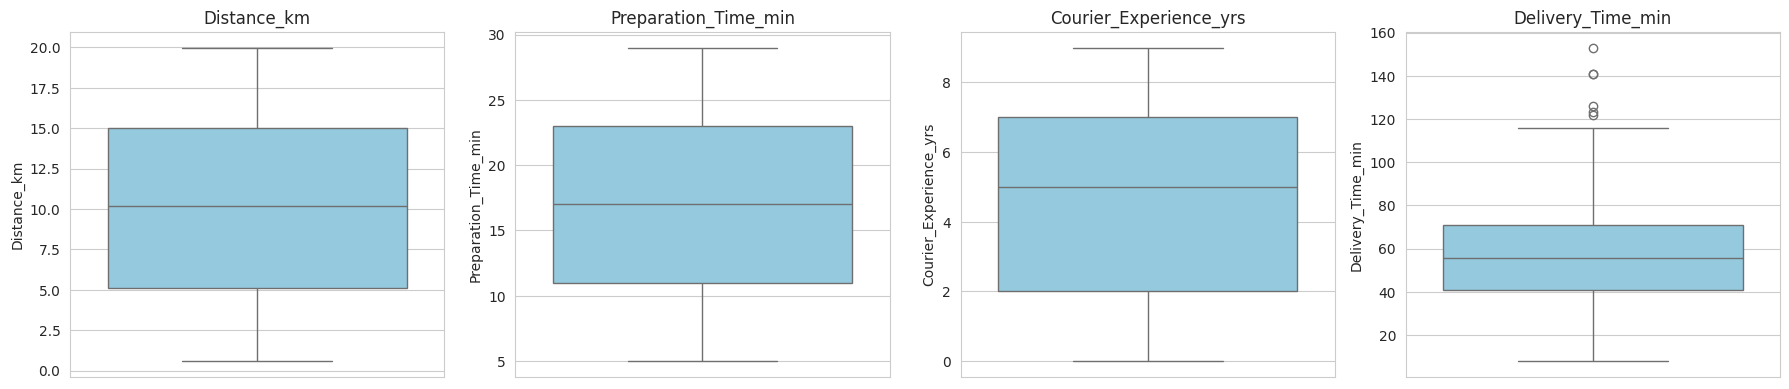

In [9]:
# Cek outlier menggunakan boxplot pada fitur numerik
num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df_clean[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col)
plt.tight_layout()
plt.show()


In [10]:
# Deteksi outlier dengan metode IQR (hanya untuk laporan, tidak langsung dihapus
# karena food delivery time secara alami bisa punya variasi besar/skewed)
def count_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return ((series < lower) | (series > upper)).sum()

for col in num_cols:
    print(f"{col}: {count_outliers_iqr(df_clean[col])} potensi outlier")


Distance_km: 0 potensi outlier
Preparation_Time_min: 0 potensi outlier
Courier_Experience_yrs: 0 potensi outlier
Delivery_Time_min: 6 potensi outlier


**Keputusan:** Outlier yang terdeteksi relatif sedikit dan bisa jadi merupakan kasus nyata (misalnya jarak sangat jauh atau cuaca ekstrem yang membuat waktu antar lama). Karena model tree-based (Random Forest, XGBoost) cukup robust terhadap outlier, kita **tidak menghapus** outlier tersebut, namun tetap kita catat sebagai konteks EDA.

## 6. Exploratory Data Analysis (EDA)

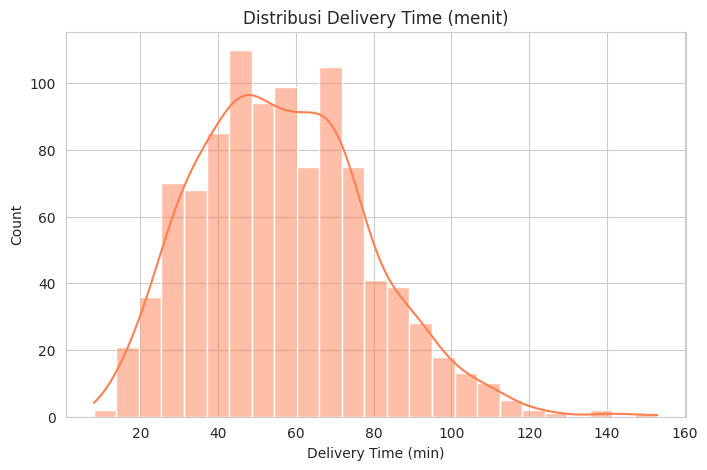

count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64


In [11]:
# Distribusi target
plt.figure(figsize=(8,5))
sns.histplot(df_clean['Delivery_Time_min'], kde=True, color='coral')
plt.title('Distribusi Delivery Time (menit)')
plt.xlabel('Delivery Time (min)')
plt.show()

print(df_clean['Delivery_Time_min'].describe())


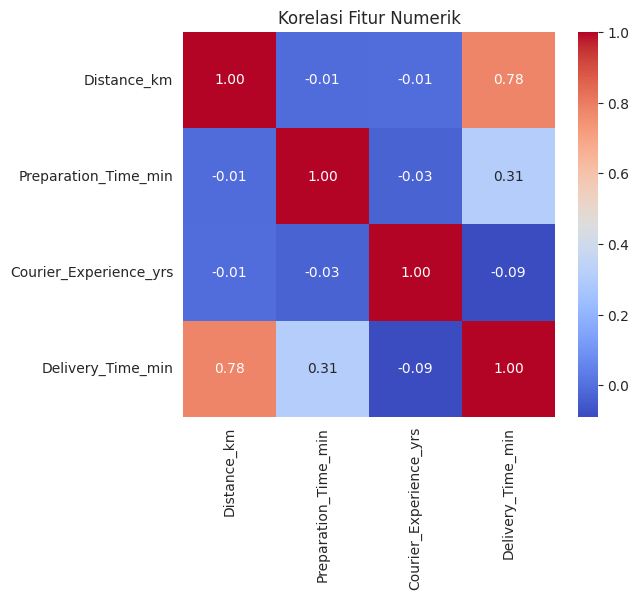

In [12]:
# Korelasi antar fitur numerik
plt.figure(figsize=(6,5))
corr = df_clean[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Fitur Numerik')
plt.show()


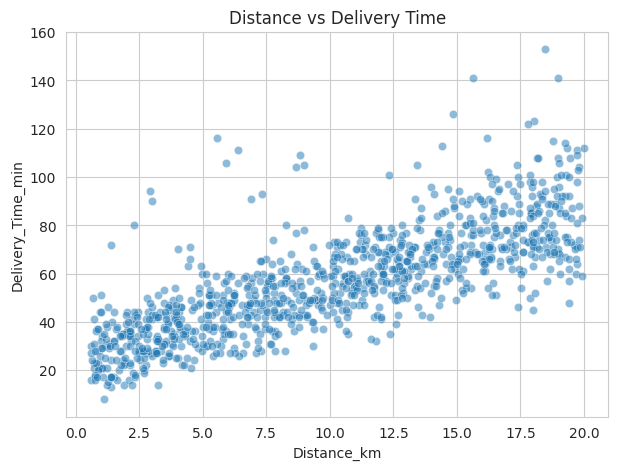

In [13]:
# Hubungan Distance_km vs Delivery_Time_min
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_clean, x='Distance_km', y='Delivery_Time_min', alpha=0.5)
plt.title('Distance vs Delivery Time')
plt.show()


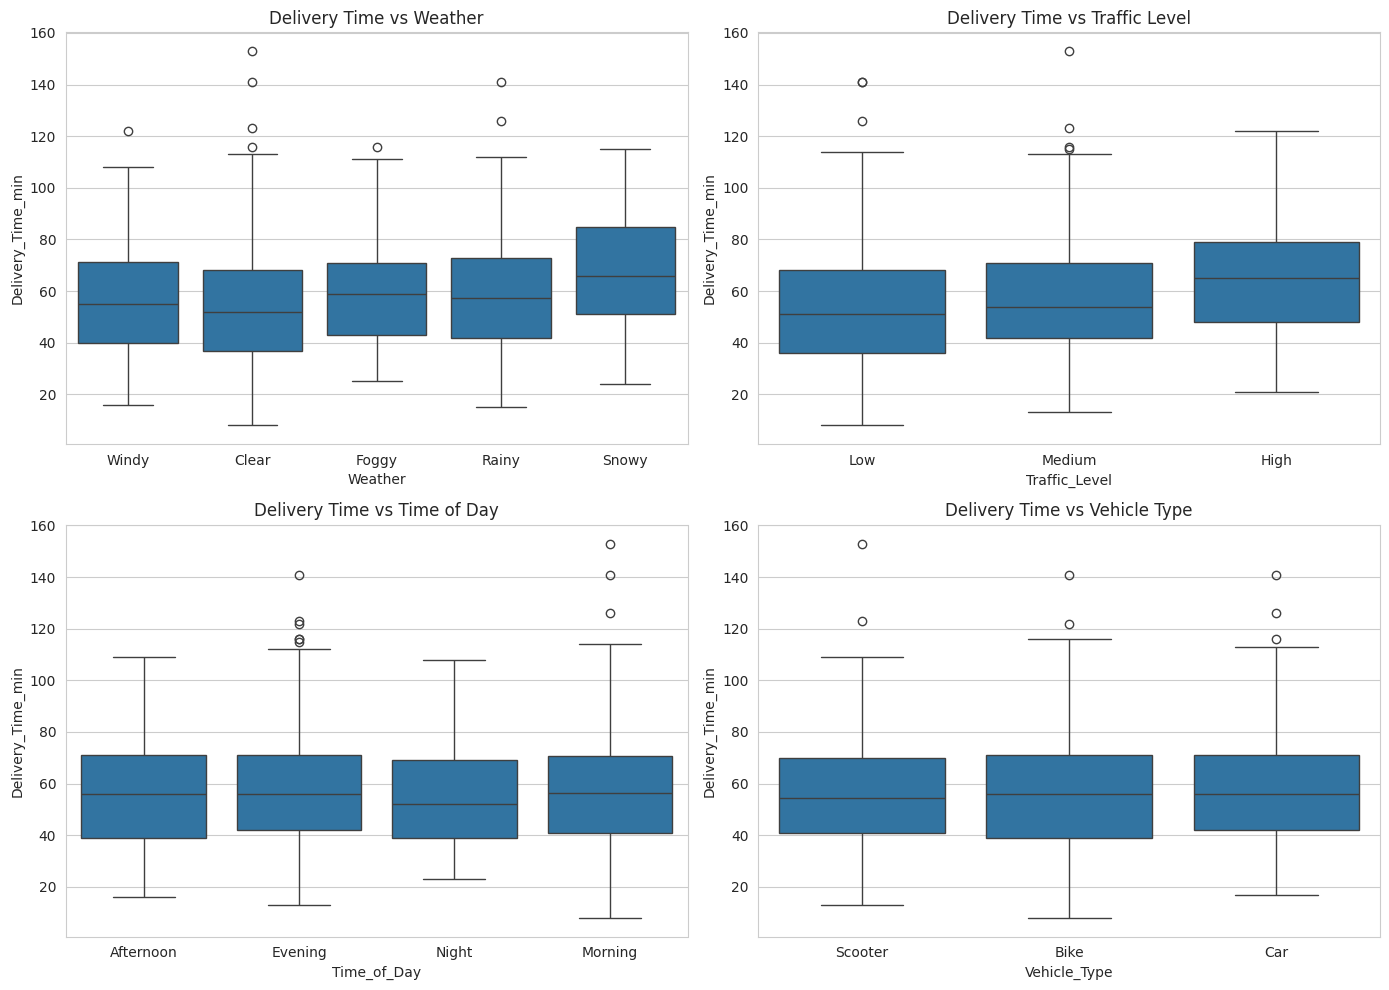

In [14]:
# Delivery time berdasarkan kategori
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df_clean, x='Weather', y='Delivery_Time_min', ax=axes[0,0])
axes[0,0].set_title('Delivery Time vs Weather')

sns.boxplot(data=df_clean, x='Traffic_Level', y='Delivery_Time_min', ax=axes[0,1],
            order=['Low','Medium','High'])
axes[0,1].set_title('Delivery Time vs Traffic Level')

sns.boxplot(data=df_clean, x='Time_of_Day', y='Delivery_Time_min', ax=axes[1,0])
axes[1,0].set_title('Delivery Time vs Time of Day')

sns.boxplot(data=df_clean, x='Vehicle_Type', y='Delivery_Time_min', ax=axes[1,1])
axes[1,1].set_title('Delivery Time vs Vehicle Type')

plt.tight_layout()
plt.show()


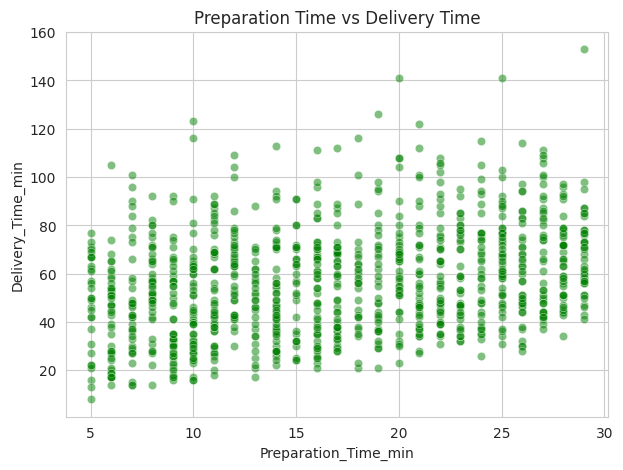

In [15]:
# Preparation time vs Delivery time
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_clean, x='Preparation_Time_min', y='Delivery_Time_min', alpha=0.5, color='green')
plt.title('Preparation Time vs Delivery Time')
plt.show()


**Insight Sementara dari EDA:**
- `Distance_km` dan `Preparation_Time_min` menunjukkan korelasi positif yang cukup jelas terhadap `Delivery_Time_min`.
- Kondisi `Traffic_Level` "High" cenderung memiliki waktu antar lebih lama dibanding "Low".
- Cuaca buruk (Snowy, Rainy, Foggy) tampak berasosiasi dengan waktu antar lebih lama dibanding Clear.
- `Vehicle_Type` dan `Time_of_Day` memberikan variasi tambahan namun tidak sekuat jarak dan waktu persiapan.


## 7. Feature Engineering

Membuat fitur tambahan yang berpotensi meningkatkan performa model:
- `Speed_Proxy`: rasio jarak terhadap waktu persiapan (indikasi tekanan operasional)
- `Is_Peak_Hour`: menandai apakah waktu pengantaran termasuk jam sibuk (Morning/Evening)
- `Experience_Level`: kategori pengalaman kurir (Junior/Mid/Senior) — untuk EDA tambahan (fitur asli numerik tetap dipakai untuk model)
- `Traffic_Weather_Interaction`: gabungan kondisi lalu lintas & cuaca yang sama-sama buruk


In [16]:
df_fe = df_clean.copy()

# 1. Rasio jarak terhadap waktu persiapan
df_fe['Distance_Prep_Ratio'] = df_fe['Distance_km'] / (df_fe['Preparation_Time_min'] + 1)

# 2. Peak hour flag (Morning & Evening dianggap jam makan sibuk)
df_fe['Is_Peak_Hour'] = df_fe['Time_of_Day'].isin(['Morning', 'Evening']).astype(int)

# 3. Kondisi buruk gabungan: traffic High ATAU cuaca buruk (Rainy/Snowy/Foggy)
bad_weather = ['Rainy', 'Snowy', 'Foggy']
df_fe['Bad_Condition'] = (
    (df_fe['Traffic_Level'] == 'High') | (df_fe['Weather'].isin(bad_weather))
).astype(int)

# 4. Kategori pengalaman kurir (untuk insight, opsional dipakai di model)
def exp_level(x):
    if x <= 2:
        return 'Junior'
    elif x <= 6:
        return 'Mid'
    else:
        return 'Senior'
df_fe['Experience_Level'] = df_fe['Courier_Experience_yrs'].apply(exp_level)

df_fe.head()


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Distance_Prep_Ratio,Is_Peak_Hour,Bad_Condition,Experience_Level
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43,0.610000,0,0,Junior
1,16.42,Clear,Medium,Evening,Bike,20,2.0,84,0.781905,1,0,Junior
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59,0.328276,0,1,Junior
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37,1.240000,0,1,Junior
4,19.03,Clear,Low,Morning,Bike,16,5.0,68,1.119412,1,0,Mid


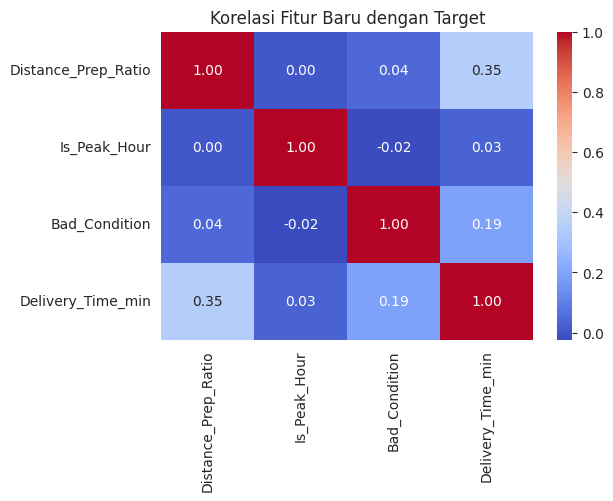

In [17]:
# Cek korelasi fitur baru terhadap target
plt.figure(figsize=(6,4))
sns.heatmap(df_fe[['Distance_Prep_Ratio','Is_Peak_Hour','Bad_Condition','Delivery_Time_min']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Fitur Baru dengan Target')
plt.show()


## 8. Data Preprocessing

Menyiapkan data untuk modeling:
- Pisahkan fitur (X) dan target (y)
- Definisikan kolom numerik dan kategorikal
- Buat `ColumnTransformer`: scaling untuk numerik (khususnya penting untuk Linear Regression), One-Hot Encoding untuk kategorikal
- Pipeline ini akan dipakai konsisten pada semua model


In [18]:
# Fitur final yang digunakan (drop Experience_Level kategorikal karena sudah terwakili oleh Courier_Experience_yrs numerik,
# untuk menghindari redundansi/multicollinearity)
feature_cols_num = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Distance_Prep_Ratio']
feature_cols_cat = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
feature_cols_binary = ['Is_Peak_Hour', 'Bad_Condition']

X = df_fe[feature_cols_num + feature_cols_cat + feature_cols_binary]
y = df_fe['Delivery_Time_min']

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()


X shape: (1000, 10)
y shape: (1000,)


,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Distance_Prep_Ratio,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Is_Peak_Hour,Bad_Condition
0,7.93,12,1.0,0.610000,Windy,Low,Afternoon,Scooter,0,0
1,16.42,20,2.0,0.781905,Clear,Medium,Evening,Bike,1,0
2,9.52,28,1.0,0.328276,Foggy,Low,Night,Scooter,0,1
3,7.44,5,1.0,1.240000,Rainy,Medium,Afternoon,Scooter,0,1
4,19.03,16,5.0,1.119412,Clear,Low,Morning,Bike,1,0


In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_cols_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), feature_cols_cat),
        ('bin', 'passthrough', feature_cols_binary)
    ]
)

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

## 9. Train-Test Split\n\nMembagi data menjadi 80% training dan 20% testing.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (800, 10)
Test shape: (200, 10)


## 10. Model Training

Melatih 4 model regresi menggunakan `Pipeline` (preprocessing + model) agar konsisten dan mencegah data leakage:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. XGBoost Regressor


In [21]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=200),
    'XGBoost': XGBRegressor(random_state=42, n_estimators=200, verbosity=0)
}

pipelines = {}
trained_models = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"{name} trained.")


Linear Regression trained.
Decision Tree trained.


Random Forest trained.
XGBoost trained.


## 11. Model Evaluation

Mengevaluasi setiap model menggunakan MAE, RMSE, dan R² pada data test.


In [22]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

results = []
predictions = {}

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    mae, rmse, r2 = evaluate_model(y_test, y_pred)
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df


,Model,MAE,RMSE,R2
0,Linear Regression,5.872955,8.777650,0.828107
1,Random Forest,6.863225,9.958201,0.778760
2,XGBoost,8.075688,11.158183,0.722228
3,Decision Tree,10.990000,16.249923,0.410879


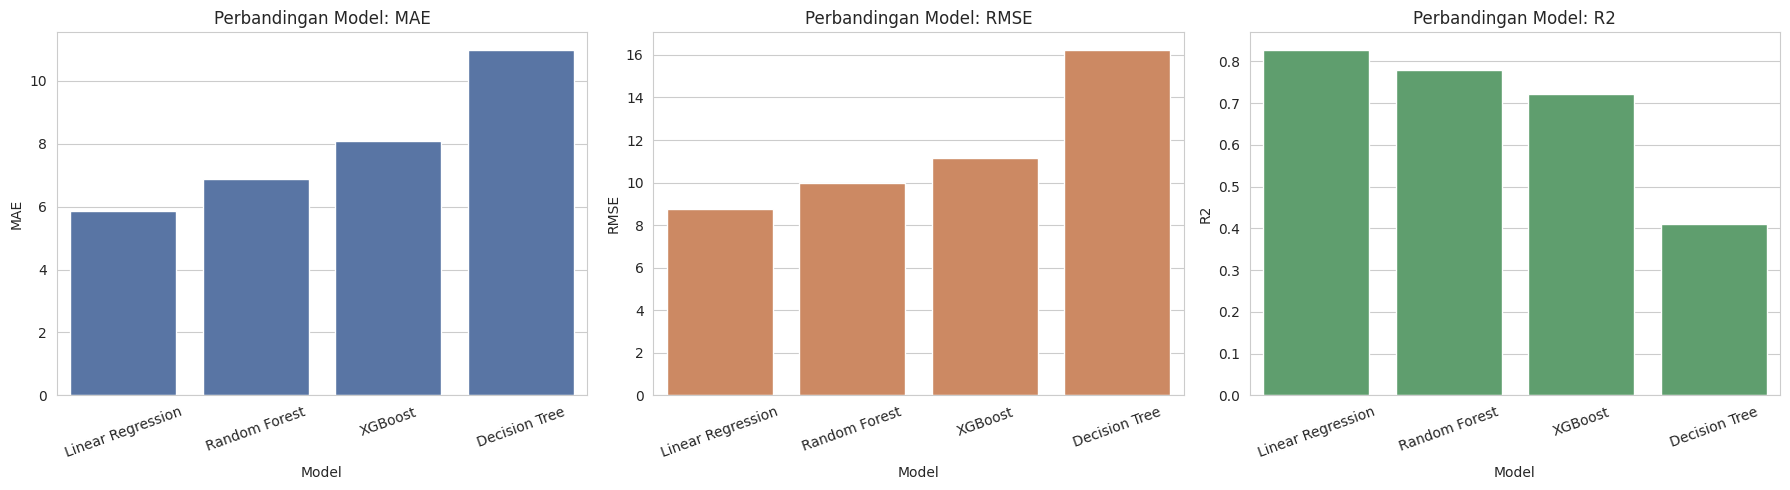

In [23]:
# Visualisasi perbandingan model
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ['MAE', 'RMSE', 'R2']
colors = ['#4C72B0', '#DD8452', '#55A868']

for ax, metric, color in zip(axes, metrics, colors):
    sns.barplot(data=results_df, x='Model', y=metric, ax=ax, color=color)
    ax.set_title(f'Perbandingan Model: {metric}')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


Model terbaik (awal, sebelum tuning): Linear Regression


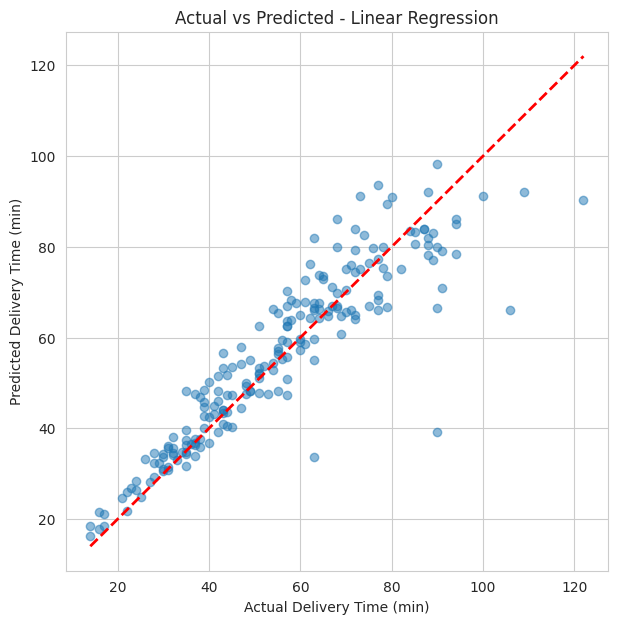

In [24]:
# Actual vs Predicted plot untuk model terbaik (berdasarkan RMSE terendah)
best_model_name = results_df.iloc[0]['Model']
print("Model terbaik (awal, sebelum tuning):", best_model_name)

plt.figure(figsize=(7,7))
plt.scatter(y_test, predictions[best_model_name], alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Delivery Time (min)')
plt.ylabel('Predicted Delivery Time (min)')
plt.title(f'Actual vs Predicted - {best_model_name}')
plt.show()


## 12. Hyperparameter Tuning

Melakukan tuning pada model terbaik menggunakan `GridSearchCV` / `RandomizedSearchCV` dengan cross-validation untuk mencari kombinasi hyperparameter optimal.


In [25]:
# Tuning dilakukan pada Random Forest & XGBoost (dua model tree-based paling kompetitif)
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10]
}

rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

rf_search = RandomizedSearchCV(
    rf_pipe, param_distributions=param_grid_rf,
    n_iter=15, cv=5, scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("Best RF params:", rf_search.best_params_)
print("Best RF CV RMSE:", -rf_search.best_score_)


Best RF params: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__max_depth': 15}
Best RF CV RMSE: 11.979169517281603


In [26]:
param_grid_xgb = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 1.0]
}

xgb_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(random_state=42, verbosity=0))
])

xgb_search = RandomizedSearchCV(
    xgb_pipe, param_distributions=param_grid_xgb,
    n_iter=20, cv=5, scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1
)
xgb_search.fit(X_train, y_train)

print("Best XGB params:", xgb_search.best_params_)
print("Best XGB CV RMSE:", -xgb_search.best_score_)


Best XGB params: {'model__subsample': 1.0, 'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best XGB CV RMSE: 11.584827613830566


In [27]:
# Evaluasi model hasil tuning pada test set
tuned_models = {
    'Random Forest (Tuned)': rf_search.best_estimator_,
    'XGBoost (Tuned)': xgb_search.best_estimator_
}

tuned_results = []
tuned_predictions = {}

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    tuned_predictions[name] = y_pred
    mae, rmse, r2 = evaluate_model(y_test, y_pred)
    tuned_results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

# Gabungkan dengan hasil sebelumnya untuk perbandingan akhir
final_results_df = pd.concat([results_df, pd.DataFrame(tuned_results)], ignore_index=True)
final_results_df = final_results_df.sort_values('RMSE').reset_index(drop=True)
final_results_df


,Model,MAE,RMSE,R2
0,Linear Regression,5.872955,8.777650,0.828107
1,XGBoost (Tuned),6.691918,9.711629,0.789580
2,Random Forest (Tuned),6.859403,9.903295,0.781193
3,Random Forest,6.863225,9.958201,0.778760
4,XGBoost,8.075688,11.158183,0.722228
5,Decision Tree,10.990000,16.249923,0.410879


In [28]:
best_final_model_name = final_results_df.iloc[0]['Model']
print("MODEL TERBAIK KESELURUHAN:", best_final_model_name)

if best_final_model_name in tuned_models:
    best_final_model = tuned_models[best_final_model_name]
else:
    best_final_model = pipelines[best_final_model_name]


MODEL TERBAIK KESELURUHAN: Linear Regression


## 13. Feature Importance

Menganalisis fitur mana yang paling berpengaruh terhadap prediksi `Delivery_Time_min`, menggunakan model terbaik (tree-based).


In [29]:
# Ambil nama fitur setelah preprocessing (one-hot encoding)
ohe = best_final_model.named_steps['preprocessor'].named_transformers_['cat']
ohe_feature_names = ohe.get_feature_names_out(feature_cols_cat)

all_feature_names = feature_cols_num + list(ohe_feature_names) + feature_cols_binary

# Ambil feature importance dari model.
# Model tree-based (RF/XGBoost/Decision Tree) punya `feature_importances_`,
# sedangkan Linear Regression menggunakan koefisien (`coef_`) sebagai proxy importance.
final_model_step = best_final_model.named_steps['model']

if hasattr(final_model_step, 'feature_importances_'):
    importances = final_model_step.feature_importances_
    imp_label = 'Importance'
elif hasattr(final_model_step, 'coef_'):
    importances = np.abs(final_model_step.coef_)  # nilai absolut koefisien sebagai ukuran pengaruh
    imp_label = 'Importance (|Coefficient|)'
else:
    raise ValueError("Model tidak memiliki feature_importances_ maupun coef_")

feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print(f"Metode importance yang digunakan: {imp_label}")
feat_imp_df


Metode importance yang digunakan: Importance (|Coefficient|)


,Feature,Importance
0,Distance_km,17.794952
1,Traffic_Level_Low,12.313437
2,Weather_Snowy,11.036834
3,Weather_Foggy,7.727317
4,Traffic_Level_Medium,6.747228
5,Preparation_Time_min,6.424059
6,Weather_Rainy,6.418388
7,Bad_Condition,2.285083
8,Courier_Experience_yrs,1.971401
9,Weather_Windy,1.501984


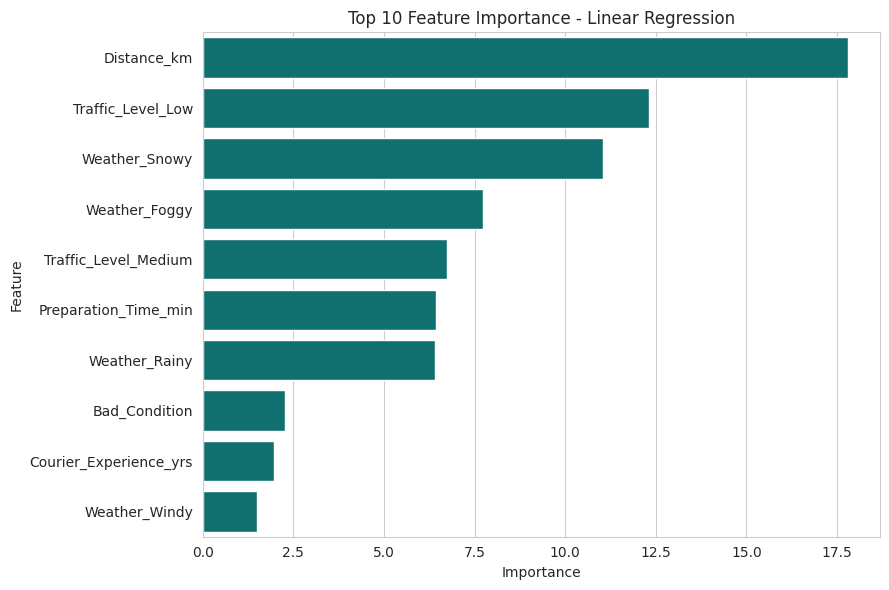

In [30]:
plt.figure(figsize=(9,6))
sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', color='teal')
plt.title(f'Top 10 Feature Importance - {best_final_model_name}')
plt.tight_layout()
plt.show()


## 14. Business Insight

**Ringkasan Hasil Model:**
- Model terbaik dipilih berdasarkan kombinasi MAE, RMSE, dan R² terendah/tertinggi pada data test (lihat tabel `final_results_df`).
- Fitur yang paling berpengaruh terhadap waktu pengantaran umumnya adalah **jarak pengiriman (`Distance_km`)** dan **waktu persiapan makanan (`Preparation_Time_min`)**, diikuti oleh kondisi lalu lintas dan cuaca.

**Rekomendasi Bisnis:**
1. **Optimasi Rute & Alokasi Kurir** — Karena jarak adalah faktor dominan, sistem dapat mengalokasikan kurir terdekat secara lebih agresif dan mempertimbangkan re-routing dinamis saat kondisi lalu lintas tinggi.
2. **Insentif untuk Kurir Berpengalaman di Kondisi Sulit** — Karena kondisi cuaca buruk/lalu lintas padat meningkatkan waktu antar, tugaskan kurir dengan pengalaman lebih tinggi pada zona/waktu berisiko tinggi tersebut.
3. **Koordinasi dengan Restoran** — Karena `Preparation_Time_min` berkontribusi signifikan, bekerja sama dengan restoran untuk mempercepat waktu masak pada jam sibuk dapat menurunkan total ETA secara efektif.
4. **ETA Dinamis untuk Pelanggan** — Gunakan model ini untuk menampilkan estimasi waktu antar yang lebih realistis kepada pelanggan berdasarkan kondisi real-time (cuaca, traffic, waktu), sehingga mengurangi komplain akibat ekspektasi yang meleset.
5. **Monitoring Model Berkelanjutan** — Karena kondisi lalu lintas dan cuaca dapat berubah musiman, model sebaiknya dilatih ulang (retrain) secara berkala dengan data terbaru agar tetap akurat.

**Keterbatasan:**
- Dataset bersifat statis (1000 baris) dan tidak mencakup data lokasi geografis atau real-time traffic API, yang dapat lebih meningkatkan akurasi jika tersedia.
- Model belum mempertimbangkan variabel seperti jumlah item pesanan atau jarak antar-restoran ke banyak titik antar dalam satu perjalanan (multi-drop delivery).

**Next Steps:**
- Menambahkan fitur real-time (GPS traffic data, cuaca live)
- Mencoba model ensemble/stacking gabungan beberapa algoritma
- Deploy model sebagai API untuk estimasi ETA secara langsung di aplikasi


## 15. Save Model & Contoh Prediksi

Setelah model terbaik terpilih, langkah selanjutnya adalah:
1. Membungkus fungsi feature engineering agar konsisten dipakai saat inference
2. Mencoba prediksi dengan contoh data baru
3. Menyimpan model (beserta seluruh pipeline preprocessing) ke file `.joblib` agar bisa dipakai di aplikasi lain (misalnya Streamlit)

**Catatan penting soal kategori input:** Dataset training menggunakan label kategori berikut. Saat membuat form input (mis. di Streamlit), gunakan label ini agar hasil prediksi valid:
- `Weather`: Clear, Rainy, Windy, Foggy, Snowy
- `Traffic_Level`: Low, Medium, High
- `Time_of_Day`: Morning, Afternoon, Evening, Night
- `Vehicle_Type`: Scooter, Bike, Car


In [31]:
import joblib

def engineer_features(raw_df):
    """
    Menerapkan feature engineering yang SAMA PERSIS seperti saat training,
    supaya konsisten saat dipakai untuk prediksi data baru.

    raw_df harus punya kolom:
    Distance_km, Weather, Traffic_Level, Time_of_Day, Vehicle_Type,
    Preparation_Time_min, Courier_Experience_yrs
    """
    df_out = raw_df.copy()
    df_out['Distance_Prep_Ratio'] = df_out['Distance_km'] / (df_out['Preparation_Time_min'] + 1)
    df_out['Is_Peak_Hour'] = df_out['Time_of_Day'].isin(['Morning', 'Evening']).astype(int)
    bad_weather = ['Rainy', 'Snowy', 'Foggy']
    df_out['Bad_Condition'] = (
        (df_out['Traffic_Level'] == 'High') | (df_out['Weather'].isin(bad_weather))
    ).astype(int)
    return df_out[feature_cols_num + feature_cols_cat + feature_cols_binary]


In [32]:
# Contoh input baru (sesuai contoh kasus)
# Distance: 6.5 km | Weather: Rain -> Rainy | Traffic: High | Time of Day: Dinner -> Evening
# Vehicle: Motorcycle -> Bike (kategori terdekat di dataset) | Prep Time: 15 min | Experience: 2 yrs

sample_input = pd.DataFrame([{
    'Distance_km': 6.5,
    'Weather': 'Rainy',
    'Traffic_Level': 'High',
    'Time_of_Day': 'Evening',
    'Vehicle_Type': 'Bike',
    'Preparation_Time_min': 15,
    'Courier_Experience_yrs': 2
}])

sample_processed = engineer_features(sample_input)
predicted_time = best_final_model.predict(sample_processed)[0]

print("=== Input Pesanan ===")
print(sample_input.to_string(index=False))
print()
print("        |")
print("        v")
print(f"  Predicted Delivery Time: {predicted_time:.0f} menit")


=== Input Pesanan ===
 Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  Preparation_Time_min  Courier_Experience_yrs
         6.5   Rainy          High     Evening         Bike                    15                       2

        |
        v
  Predicted Delivery Time: 57 menit


In [33]:
# Simpan model terbaik (pipeline lengkap: preprocessing + model) ke joblib
joblib.dump(best_final_model, 'best_delivery_model.joblib')

# Simpan juga konfigurasi fitur agar aplikasi Streamlit tahu kolom apa saja yang dipakai
feature_config = {
    'feature_cols_num': feature_cols_num,
    'feature_cols_cat': feature_cols_cat,
    'feature_cols_binary': feature_cols_binary,
    'best_model_name': best_final_model_name,
    'weather_options': sorted(df_clean['Weather'].unique().tolist()),
    'traffic_options': ['Low', 'Medium', 'High'],
    'time_of_day_options': ['Morning', 'Afternoon', 'Evening', 'Night'],
    'vehicle_options': sorted(df_clean['Vehicle_Type'].unique().tolist())
}
joblib.dump(feature_config, 'feature_config.joblib')

print("Model tersimpan sebagai 'best_delivery_model.joblib'")
print("Konfigurasi fitur tersimpan sebagai 'feature_config.joblib'")
print("Model terbaik yang disimpan:", best_final_model_name)


Model tersimpan sebagai 'best_delivery_model.joblib'
Konfigurasi fitur tersimpan sebagai 'feature_config.joblib'
Model terbaik yang disimpan: Linear Regression
